In [1]:
!git clone https://github.com/michaelmoreno101010/filtro-hojas-de-vida.git
%cd filtro-hojas-de-vida
!pip install -q pytest
!python -m pytest -q
!python -m src.generar_datos

Cloning into 'filtro-hojas-de-vida'...
remote: Enumerating objects: 55, done.
remote: Counting objects: 100% (55/55), done.
remote: Compressing objects: 100% (41/41), done.
remote: Total 55 (delta 10), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (55/55), 33.33 KiB | 4.17 MiB/s, done.
Resolving deltas: 100% (10/10), done.
/content/filtro-hojas-de-vida

no tests ran in 0.03s
Datos generados en: /content/filtro-hojas-de-vida/data
  Ofertas: 10 | CVs: 400 (300 base + 100 gemelos) | Pares: 4000
  Pares por nivel de relevancia: {'0': 3590, '1': 108, '2': 105, '3': 197}
  CVs por género: {'F': 200, 'M': 200}
  sha256 ofertas.csv: 1d29145234150f99...
  sha256 cvs.csv: 817c59483fb51a43...
  sha256 relevancia.csv: ec721c5d1bf27c78...


Tamaños: (400, 11) (10, 9) (4000, 3)
Faltantes en CVs: 0
Textos de CV duplicados: 0
genero                 F   M
rol                         
analista_datos        15  15
analista_financiero   15  15
contador              15  15
desarrollador_web     15  15
docente_primaria      15  15
enfermeria            15  15
ingeniero_civil       15  15
ingeniero_industrial  15  15
marketing_digital     15  15
nutricion             15  15
count    400.0
mean      96.2
std       16.5
min       58.0
25%       86.0
50%       96.0
75%      108.0
max      137.0
Name: palabras, dtype: float64
Relevancia media por género:
genero
F    0.229
M    0.226
Name: relevancia, dtype: float64
Pares por partición y nivel de relevancia:
relevancia     0   1   2    3
particion                    
dev         1794  51  50  105
test        1796  57  55   92


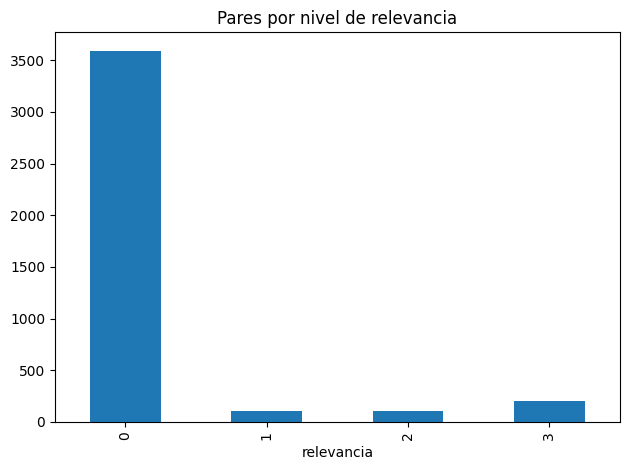

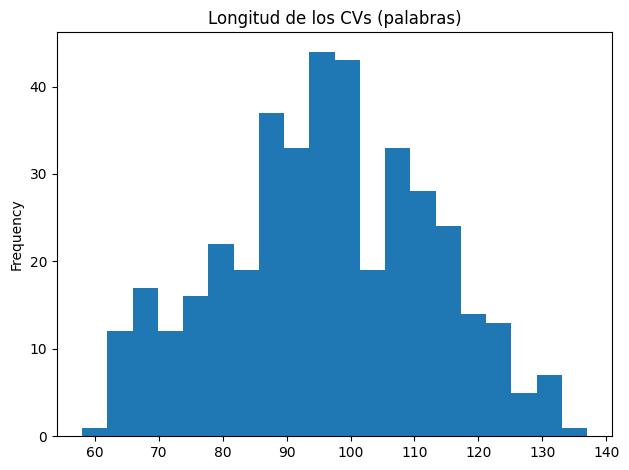

In [2]:
import os
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("results", exist_ok=True)
cvs = pd.read_csv("data/cvs.csv")
ofertas = pd.read_csv("data/ofertas.csv")
rel = pd.read_csv("data/relevancia.csv")

print("Tamaños:", cvs.shape, ofertas.shape, rel.shape)
print("Faltantes en CVs:", int(cvs.isna().sum().sum()))
print("Textos de CV duplicados:", int(cvs.texto.duplicated().sum()))
print(cvs[cvs.es_gemelo == 0].groupby(["rol", "genero"]).size().unstack())

cvs["palabras"] = cvs.texto.str.split().str.len()
print(cvs.palabras.describe().round(1))

r = rel.merge(cvs[["cv_id", "genero"]], on="cv_id").merge(ofertas[["oferta_id", "particion"]], on="oferta_id")
print("Relevancia media por género:")
print(r.groupby("genero").relevancia.mean().round(3))
print("Pares por partición y nivel de relevancia:")
print(r.groupby("particion").relevancia.value_counts().unstack().fillna(0).astype(int))

rel.relevancia.value_counts().sort_index().plot.bar(title="Pares por nivel de relevancia")
plt.tight_layout(); plt.savefig("results/eda_relevancia.png", dpi=100); plt.show()
cvs.palabras.plot.hist(bins=20, title="Longitud de los CVs (palabras)")
plt.tight_layout(); plt.savefig("results/eda_longitud.png", dpi=100); plt.show()

In [3]:
fila = cvs[cvs.es_gemelo == 1].iloc[0]
print(cvs[cvs.cv_id == fila.grupo_id].iloc[0].texto)
print("\n" + "=" * 50 + "\n")
print(fila.texto)

Felipe Londoño Ríos
Analista de información

PERFIL
Egresado de Economía, motivado por aprender y aportar en equipos de producto.

EDUCACIÓN
- Economía, Corporación Universitaria Horizonte Sur (2023)

EXPERIENCIA
- Analista de información, Grupo Arrayán (2024-actualidad): Uso diario de diseño de interfaces web y hojas de cálculo; trabajo en equipo con otras áreas.

HABILIDADES
diseño de interfaces web, Git, hojas de cálculo, business intelligence, JavaScript, data visualization

IDIOMAS
Español (nativo); inglés (básico)


Isabela Londoño Ríos
Analista de información

PERFIL
Egresada de Economía, motivada por aprender y aportar en equipos de producto.

EDUCACIÓN
- Economía, Corporación Universitaria Horizonte Sur (2023)

EXPERIENCIA
- Analista de información, Grupo Arrayán (2024-actualidad): Uso diario de diseño de interfaces web y hojas de cálculo; trabajo en equipo con otras áreas.

HABILIDADES
diseño de interfaces web, Git, hojas de cálculo, business intelligence, JavaScript, data vi

In [4]:
!find . -path ./.git -prune -o -type f -print | sort
!wc -l tests/*.py

./configs/catalogo.json
./configs/generacion.json
./data/cvs.csv
./data/metadatos.json
./data/ofertas.csv
./data/relevancia.csv
./docs/decision_datos.md
./docs/docs/referencias.md
./docs/ficha_datos
./docs/planteamiento.md
./.gitignore
./.pytest_cache/CACHEDIR.TAG
./.pytest_cache/.gitignore
./.pytest_cache/README.md
./.pytest_cache/v/cache/nodeids
./README.md
./requirements.txt
./results/eda_longitud.png
./results/eda_relevancia.png
./src/generar_datos.py
./src/__init__.py
./src/__pycache__/generar_datos.cpython-313.pyc
./src/__pycache__/__init__.cpython-313.pyc
./tests/__pycache__/test_generar_datos.cpython-313-pytest-8.4.2.pyc
./tests/test_generar_datos.py
544 tests/test_generar_datos.py


In [5]:
%cd /content
!rm -rf filtro-hojas-de-vida
!git clone https://github.com/michaelmoreno101010/filtro-hojas-de-vida.git
%cd filtro-hojas-de-vida
!pip install -q pytest
!head -3 tests/test_generar_datos.py
!grep -c "^def test_" tests/test_generar_datos.py
!python -m pytest -q
!find docs -type f
!pip list 2>/dev/null | grep -i -E "^(pandas|matplotlib|pytest) "

/content
Cloning into 'filtro-hojas-de-vida'...
remote: Enumerating objects: 73, done.
remote: Counting objects: 100% (73/73), done.
remote: Compressing objects: 100% (58/58), done.
remote: Total 73 (delta 18), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (73/73), 69.76 KiB | 4.10 MiB/s, done.
Resolving deltas: 100% (18/18), done.
/content/filtro-hojas-de-vida
"""Pruebas del generador de datos sintéticos.

Se ejecutan con:  python -m pytest -q
20
....................                                                     [100%]
20 passed in 1.15s
docs/declaracion_ia.md
docs/referencias.md
docs/ficha_datos.md
docs/planteamiento.md
docs/decision_datos.md
matplotlib                            3.10.0
pandas                                2.2.3
pytest                                8.4.2


In [6]:
%cd /content
!rm -rf filtro-hojas-de-vida
!git clone https://github.com/michaelmoreno101010/filtro-hojas-de-vida.git
%cd filtro-hojas-de-vida
!pip install -q pytest
!python -m pytest -q
!python -m src.generar_datos
!python -m src.linea_base --particion dev

/content
Cloning into 'filtro-hojas-de-vida'...
remote: Enumerating objects: 88, done.
remote: Counting objects: 100% (88/88), done.
remote: Compressing objects: 100% (72/72), done.
remote: Total 88 (delta 23), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (88/88), 77.52 KiB | 2.04 MiB/s, done.
Resolving deltas: 100% (23/23), done.
/content/filtro-hojas-de-vida
..............................                                           [100%]
30 passed in 0.96s
Datos generados en: /content/filtro-hojas-de-vida/data
  Ofertas: 10 | CVs: 400 (300 base + 100 gemelos) | Pares: 4000
  Pares por nivel de relevancia: {'0': 3590, '1': 108, '2': 105, '3': 197}
  CVs por género: {'F': 200, 'M': 200}
  sha256 ofertas.csv: 1d29145234150f99...
  sha256 cvs.csv: 817c59483fb51a43...
  sha256 relevancia.csv: ec721c5d1bf27c78...
E-01 BM25 (k1=1.5, b=0.75) | partición: dev | resultados por oferta en /content/filtro-hojas-de-vida/results/e01_bm25_dev.csv
método         ndcg@10          

In [7]:
%cd /content
!rm -rf filtro-hojas-de-vida
!git clone https://github.com/michaelmoreno101010/filtro-hojas-de-vida.git
%cd filtro-hojas-de-vida
!pip install -q pytest sentence-transformers
!python -m pytest -q
!python -m src.generar_datos
!python -m src.linea_base --particion dev
!python -m src.embeddings --id E-02 --max-seq 128 --particion dev
!python -m src.embeddings --id E-03 --max-seq 256 --particion dev

/content
Cloning into 'filtro-hojas-de-vida'...
remote: Enumerating objects: 100, done.
remote: Counting objects: 100% (100/100), done.
remote: Compressing objects: 100% (84/84), done.
remote: Total 100 (delta 29), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (100/100), 83.75 KiB | 2.09 MiB/s, done.
Resolving deltas: 100% (29/29), done.
/content/filtro-hojas-de-vida
.................................                                        [100%]
33 passed in 1.34s
Datos generados en: /content/filtro-hojas-de-vida/data
  Ofertas: 10 | CVs: 400 (300 base + 100 gemelos) | Pares: 4000
  Pares por nivel de relevancia: {'0': 3590, '1': 108, '2': 105, '3': 197}
  CVs por género: {'F': 200, 'M': 200}
  sha256 ofertas.csv: 1d29145234150f99...
  sha256 cvs.csv: 817c59483fb51a43...
  sha256 relevancia.csv: ec721c5d1bf27c78...
E-01 BM25 (k1=1.5, b=0.75) | partición: dev | resultados por oferta en /content/filtro-hojas-de-vida/results/e01_bm25_dev.csv
método         ndcg@10    

In [1]:
%cd /content
!rm -rf filtro-hojas-de-vida
!git clone https://github.com/michaelmoreno101010/filtro-hojas-de-vida.git
%cd filtro-hojas-de-vida
!pip install -q pytest sentence-transformers
!python -m pytest -q
!python -m src.generar_datos
!python -m src.auditoria --metodo bm25 --particion dev
!python -m src.auditoria --metodo embeddings --max-seq 128 --particion dev

/content
Cloning into 'filtro-hojas-de-vida'...
remote: Enumerating objects: 108, done.
remote: Counting objects: 100% (108/108), done.
remote: Compressing objects: 100% (92/92), done.
remote: Total 108 (delta 33), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (108/108), 90.09 KiB | 1.96 MiB/s, done.
Resolving deltas: 100% (33/33), done.
/content/filtro-hojas-de-vida
........................................                                 [100%]
40 passed in 1.71s
Datos generados en: /content/filtro-hojas-de-vida/data
  Ofertas: 10 | CVs: 400 (300 base + 100 gemelos) | Pares: 4000
  Pares por nivel de relevancia: {'0': 3590, '1': 108, '2': 105, '3': 197}
  CVs por género: {'F': 200, 'M': 200}
  sha256 ofertas.csv: 1d29145234150f99...
  sha256 cvs.csv: 817c59483fb51a43...
  sha256 relevancia.csv: ec721c5d1bf27c78...
AUDITORÍA {'metodo': 'bm25'} | partición: dev | pares gemelos x ofertas: 500
  Gemela (F) con mayor puntaje: 0.0% | gemelo (M): 7.8% | empates: 92.2%
  

In [2]:
%cd /content
!rm -rf filtro-hojas-de-vida
!git clone https://github.com/michaelmoreno101010/filtro-hojas-de-vida.git
%cd filtro-hojas-de-vida
!pip install -q pytest sentence-transformers
!python -m pytest -q
!python -m src.generar_datos
!python -m src.linea_base --particion dev
!python -m src.mitigacion --particion dev

/content
Cloning into 'filtro-hojas-de-vida'...
remote: Enumerating objects: 116, done.
remote: Counting objects: 100% (116/116), done.
remote: Compressing objects: 100% (100/100), done.
remote: Total 116 (delta 37), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (116/116), 94.14 KiB | 1.81 MiB/s, done.
Resolving deltas: 100% (37/37), done.
/content/filtro-hojas-de-vida
...........................................                              [100%]
43 passed in 1.57s
Datos generados en: /content/filtro-hojas-de-vida/data
  Ofertas: 10 | CVs: 400 (300 base + 100 gemelos) | Pares: 4000
  Pares por nivel de relevancia: {'0': 3590, '1': 108, '2': 105, '3': 197}
  CVs por género: {'F': 200, 'M': 200}
  sha256 ofertas.csv: 1d29145234150f99...
  sha256 cvs.csv: 817c59483fb51a43...
  sha256 relevancia.csv: ec721c5d1bf27c78...
E-01 BM25 (k1=1.5, b=0.75) | partición: dev | resultados por oferta en /content/filtro-hojas-de-vida/results/e01_bm25_dev.csv
método         ndcg@10  

In [3]:
%cd /content
!rm -rf filtro-hojas-de-vida
!git clone https://github.com/michaelmoreno101010/filtro-hojas-de-vida.git
%cd filtro-hojas-de-vida
!pip install -q pytest sentence-transformers
!python -m pytest -q
!python -m src.generar_datos
!python -m src.hibrido --particion dev

/content
Cloning into 'filtro-hojas-de-vida'...
remote: Enumerating objects: 124, done.
remote: Counting objects: 100% (124/124), done.
remote: Compressing objects: 100% (108/108), done.
remote: Total 124 (delta 42), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (124/124), 97.73 KiB | 1.95 MiB/s, done.
Resolving deltas: 100% (42/42), done.
/content/filtro-hojas-de-vida
..............................................                           [100%]
46 passed in 2.63s
Datos generados en: /content/filtro-hojas-de-vida/data
  Ofertas: 10 | CVs: 400 (300 base + 100 gemelos) | Pares: 4000
  Pares por nivel de relevancia: {'0': 3590, '1': 108, '2': 105, '3': 197}
  CVs por género: {'F': 200, 'M': 200}
  sha256 ofertas.csv: 1d29145234150f99...
  sha256 cvs.csv: 817c59483fb51a43...
  sha256 relevancia.csv: ec721c5d1bf27c78...
Loading weights: 100% 199/199 [00:00<00:00, 16632.79it/s]
E-05 híbrido (RRF k=60) | {'modelo': 'sentence-transformers/paraphrase-multilingual-MiniLM-L

In [4]:
%cd /content
!rm -rf filtro-hojas-de-vida
!git clone https://github.com/michaelmoreno101010/filtro-hojas-de-vida.git
%cd filtro-hojas-de-vida
!pip install -q pytest sentence-transformers
!python -m src.generar_datos
!python -m src.linea_base --particion test
!python -m src.mitigacion --particion test
!python -m src.auditoria --metodo bm25 --particion test

/content
Cloning into 'filtro-hojas-de-vida'...
remote: Enumerating objects: 136, done.
remote: Counting objects: 100% (136/136), done.
remote: Compressing objects: 100% (120/120), done.
remote: Total 136 (delta 48), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (136/136), 103.78 KiB | 2.12 MiB/s, done.
Resolving deltas: 100% (48/48), done.
/content/filtro-hojas-de-vida
Datos generados en: /content/filtro-hojas-de-vida/data
  Ofertas: 10 | CVs: 400 (300 base + 100 gemelos) | Pares: 4000
  Pares por nivel de relevancia: {'0': 3590, '1': 108, '2': 105, '3': 197}
  CVs por género: {'F': 200, 'M': 200}
  sha256 ofertas.csv: 1d29145234150f99...
  sha256 cvs.csv: 817c59483fb51a43...
  sha256 relevancia.csv: ec721c5d1bf27c78...
E-01 BM25 (k1=1.5, b=0.75) | partición: test | resultados por oferta en /content/filtro-hojas-de-vida/results/e01_bm25_test.csv
método         ndcg@10           mrr  precision@10     recall@10     recall@30
bm25             0.790         0.900     